In [1]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import sys
import scipy.optimize as spopt  # Optimization algorithms
import scipy.stats as st
from scipy.stats import gaussian_kde

# from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [2]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band = 'r'  # Band used for magnitude measurement
color_band_1 = 'r'  # First band for color (e.g. r-z)
color_band_2 = 'z'  # Second band for color
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

# === CMD Parameters === 
default_color_cut = 0 # OG default_color_cut = 1.06
magnitude_cut = 17.3
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

# === Color and Magnitude (Optional) Adjustments ===
# Adjust defaults for specific color combinations
if color_band_2 == "z" and color_band_1 == "r":
    default_color_cut = 0 # OG default_color_cut = 0.46
    color_range_max = 1.0
    msto_shift_value = 3.0
    
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

# print("Using magnitude and color bands:", magnitude_band, color_band_1, color_band_2)

# === Load Configuration from Options File ===
options = pyp2options.pip2options('/home/bernthold.17/SURP2025/fit_models/')

# Column indices for magnitudes
mag_col_index = options['cmdm-' + magnitude_band] - 1
c1_col_index = options['cmdm-' + color_band_1] - 1
c2_col_index = options['cmdm-' + color_band_2] - 1

# Column indices for position
ra_col_index = 1
dec_col_index = 2

# === Quality Filters ===
# Column indices for quality flags
qflag_mag = options['cmdq-' + magnitude_band] - 1
qflag_c1 = options['cmdq-' + color_band_1] - 1
qflag_c2 = options['cmdq-' + color_band_2] - 1

# === Output Reference Directory ===
reference_directory = '/home/bernthold.17/SURP2025/fit_models/'

# === Image Grid Dimensions ===
grid_cols = 4
grid_rows = 8
subimage_size = 2048.0 / grid_cols

# === Red Clump Color Reference Function ===
# The numbers come from the Nataf papers --> Nataf et al. (2015) Table 1: Extinction Curve Variations in VIJK
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0, 0)
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    # Use the relations between U, B, V, R, I mags and Sloan Digital Sky Survey (SDSS) u, g, r, i, z mags to get 
     # the g, r, i, z mags
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    # print("r sdss:", r_sdss, rgbb_r_sdss, agbb_r_sdss)
    # print("gmi sdss:", gmi_sdss, rgbb_gmi_sdss, agbb_gmi_sdss)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

# === Load Photometric Catalog ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"

try:
    # Load as DataFrame first, which is best for type conversions
    photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace = True, comment = '#', header = None)

    # List of column indices that MUST be numeric
    # Include all columns that will be used for calculations or selection
    numeric_cols_to_convert = list(set([
        mag_col_index, c1_col_index, c2_col_index,
        ra_col_index, dec_col_index,
        qflag_mag, qflag_c1, qflag_c2
    ]))
    numeric_cols_to_convert.sort() # Ensure consistent order

    # Apply pd.to_numeric to these specific columns in the DataFrame
    for col_idx in numeric_cols_to_convert:
        if col_idx < photometric_catalog_df.shape[1]:
            photometric_catalog_df.iloc[:, col_idx] = pd.to_numeric(
                photometric_catalog_df.iloc[:, col_idx], errors='coerce'
            )
        else:
            print(f"Warning: Column index {col_idx} for conversion is out of bounds for the loaded catalog. Skipping conversion for this column.")

    # Create a new NumPy array containing only these relevant columns,
    # and explicitly cast them to float. This ensures a homogeneous numeric array.
    try:
        photometric_catalog = photometric_catalog_df.iloc[:, numeric_cols_to_convert].values.astype(float)

        # Update your column indices to reflect their new positions in this smaller array
        # This is crucial for all subsequent indexing
        original_to_new_indices = {original_idx: new_idx for new_idx, original_idx in enumerate(numeric_cols_to_convert)}

        new_mag_col_index = original_to_new_indices[mag_col_index]
        new_c1_col_index = original_to_new_indices[c1_col_index]
        new_c2_col_index = original_to_new_indices[c2_col_index]
        new_ra_col_index = original_to_new_indices[ra_col_index]
        new_dec_col_index = original_to_new_indices[dec_col_index]
        new_qflag_mag = original_to_new_indices[qflag_mag]
        new_qflag_c1 = original_to_new_indices[qflag_c1]
        new_qflag_c2 = original_to_new_indices[qflag_c2]

    except ValueError as e:
        print(f"Critical Error: Could not convert selected columns to float during initial catalog processing: {e}")
        print("This usually means there are truly non-numeric values in the raw data that 'errors=coerce' couldn't handle, or a column index is wrong.")
        sys.exit(1)

    # Print dtypes of potentially problematic columns in photometric_catalog (using new indices)
    # print(f"Dtype of mag_col_index ({new_mag_col_index}) in photometric_catalog: {photometric_catalog[:, new_mag_col_index].dtype}")
    # print(f"Dtype of c1_col_index ({new_c1_col_index}) in photometric_catalog: {photometric_catalog[:, new_c1_col_index].dtype}")
    # print(f"Dtype of c2_col_index ({new_c2_col_index}) in photometric_catalog: {photometric_catalog[:, new_c2_col_index].dtype}")
    # print(f"Dtype of ra_col_index ({new_ra_col_index}) in photometric_catalog: {photometric_catalog[:, new_ra_col_index].dtype}")
    # print(f"Dtype of dec_col_index ({new_dec_col_index}) in photometric_catalog: {photometric_catalog[:, new_dec_col_index].dtype}")
    # print(f"Dtype of qflag_c1 ({new_qflag_c1}) in photometric_catalog: {photometric_catalog[:, new_qflag_c1].dtype}")


except Exception as error:
    print(f"Error loading catalog: {error}")
    sys.exit(1)
else:
    # Calculate min/max RA/Dec from the photometric_catalog (using new indices)
    ra_min = np.nanmin(photometric_catalog[:, new_ra_col_index])
    ra_max = np.nanmax(photometric_catalog[:, new_ra_col_index])
    dec_min = np.nanmin(photometric_catalog[:, new_dec_col_index])
    dec_max = np.nanmax(photometric_catalog[:, new_dec_col_index])

# === Position Adjustments === 
# Optional positional filtering via RA/Dec limits
apply_position_cut = False
ra_min, ra_max = -1, -1
dec_min, dec_max = -1, -1


# If you've given it an explicit position cut, use those values. Else use the min and max RA and Dec from the data
if apply_position_cut==True:
    photometric_catalog = photometric_catalog[(photometric_catalog[:, new_ra_col_index] >= ra_min) & 
                                              (photometric_catalog[:, new_ra_col_index] < ra_max) & 
                                              (photometric_catalog[:, new_dec_col_index] >= dec_min) & 
                                              (photometric_catalog[:, new_dec_col_index] < dec_max)]
    
# === Apply Quality Filters to the Photometric Catalog ===
# Apply magnitude quality flag filters 
valid_quality = (
    #(photometric_catalog[:, qflag_mag] == 1) &
    (photometric_catalog[:, new_qflag_c1] == 1) &
    (photometric_catalog[:, new_qflag_c2] == 1)
)
filtered_catalog = photometric_catalog[valid_quality]
# print(f"Stars passing quality cuts: {len(filtered_catalog)}")

# === Optional Position Filtering ===
# Optional position-based filtering using RA/Dec limits
if apply_position_cut:
    ra_values = filtered_catalog[:, new_ra_col_index]
    dec_values = filtered_catalog[:, new_dec_col_index]
    within_bounds = (
        (ra_values > ra_min) & (ra_values < ra_max) &
        (dec_values > dec_min) & (dec_values < dec_max)
    )
    filtered_catalog = filtered_catalog[within_bounds]

# print(f"Stars within RA/Dec bounds: {len(filtered_catalog)}")

# === Galactic Coordinates ===
# Get the mean RA and Dec
ra = np.nanmean(filtered_catalog[:, new_ra_col_index])
dec = np.nanmean(filtered_catalog[:, new_dec_col_index])

# Get the l and b coordinates
coords = SkyCoord(ra, dec, frame = 'icrs', unit = u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
# print("Galactic Coordinates:",l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = red_clump_color(l, b)

clumpmag0 = red_clump["clump-" + magnitude_band]
rgbbmag0 = red_clump["rgbb-" + magnitude_band]
agbbmag0 = red_clump["agbb-" + magnitude_band]

# === Red Clump Model (Quadratic + Gaussian) ===
def rcmodel(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0))**2/sigma_rc**2)
    return A + B + C + D     

# === Red Clump Gaussian ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

# === Construct Color-Magnitude Diagram (CMD) ===
# Compute color index and magnitude
color_index = filtered_catalog[:, new_c1_col_index] - filtered_catalog[:, new_c2_col_index]
magnitude_values = filtered_catalog[:, new_mag_col_index]

# === Giant Star Selection ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates = filtered_catalog[(color_index > default_color_cut) & (magnitude_values < magnitude_cut)]

giant_colors = giant_candidates[:, new_c1_col_index] - giant_candidates[:, new_c2_col_index]
giant_magnitudes = giant_candidates[:, new_mag_col_index]

print(f"Selected {len(giant_candidates)} giant star candidates")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant, bin_edges_giant = np.histogram(giant_magnitudes, range = (magnitude_cut - 4.0,magnitude_cut), 
                                                  bins = 40, density = False) # bins the magnitudes of the giants
bin_centers_giant = 0.5 * (bin_edges_giant[0:-1] + bin_edges_giant[1:]) # calculates bin centers from the bin edges

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0 = (hist_counts_giant>0)
hist_counts_m0 = hist_counts_giant[mask_0]
bin_centers_m0 = bin_centers_giant[mask_0]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit


par_0, cov_0 = spopt.curve_fit(rcmodel, bin_centers_m0, hist_counts_m0, p0 = initial_guess_0, 
                              sigma = np.sqrt(hist_counts_m0))
# print(f"rcmodel Fit Results:\nAmplitude = {par_0[0]:.2f}\n  Slope = {par_0[1]:.2f}\n Magnitude of red clump = {par_0[2]:.2f}\n  Number of red clump stars = {par_0[3]:.2f}\n  Sigma = {par_0[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0

# print(f"Giant magnitude range: {np.min(giant_candidates[:, mag_col_index])} to {np.max(giant_candidates[:, mag_col_index])}")

# === Red Clump Star Selection ===
# Filter stars that are likely within the red clump
clump_candidates = giant_candidates[np.abs(giant_candidates[:, new_mag_col_index] - par_0[2]) < 2 * par_0[4]]

clump_colors = clump_candidates[:, new_c1_col_index] - clump_candidates[:, new_c2_col_index]
clump_magnitudes = clump_candidates[:, new_mag_col_index]

print(f"Selected {len(clump_candidates)} red clump candidates")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump, bin_edges_clump = np.histogram(clump_colors, range = (default_color_cut, default_color_cut + 1.5), 
                                                  bins=60)
bin_centers_clump = 0.5 * (bin_edges_clump[:-1] + bin_edges_clump[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1 = (hist_counts_clump>0)
hist_counts_m1 = hist_counts_clump[mask_1]
bin_centers_m1 = bin_centers_clump[mask_1]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0[3] + 0.0, default_color_cut + 0.2, 0.2]

par_1, cov_1 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0 = initial_guess_1, 
                               sigma=np.sqrt(hist_counts_m1))
# print(f"cgauss Model Fit Results:\nAmplitude = {par_1[0]:.2f}\n  Mean = {par_1[1]:.2f}\n Sigma = {par_1[2]:.2f}")

amplitude, mean, sigma = par_1

/home/bernthold.17/SURP2025/fit_models/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)
/tmp/slurmtmp.8793078/ipykernel_3258264/387480428.py:123: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace = True, comment = '#', header = None)


Selected 1891 giant star candidates
Selected 1669 red clump candidates


In [3]:
# === Calculate the 1D KDE for Giant and Clump Candidates ===
# Filter out extreme values (if any) to avoid over-smoothing
kde_giant_magnitudes = giant_magnitudes[(giant_magnitudes > 14) & (giant_magnitudes < 18)]
kde_giant_magnitudes = np.array(kde_giant_magnitudes, dtype=float)
kde_giant_magnitudes = kde_giant_magnitudes[np.isfinite(kde_giant_magnitudes)]

kde_clump_colors = clump_colors[(clump_colors > 0.5) & (clump_colors < 1.6)]
kde_clump_colors = np.array(kde_clump_colors, dtype=float)
kde_clump_colors = kde_clump_colors[np.isfinite(kde_clump_colors)]

# Fit KDE
kde_giant_mag = gaussian_kde(kde_giant_magnitudes)
kde_clump_col = gaussian_kde(kde_clump_colors)

# Evaluation grid
x_giant_mag = np.linspace(np.min(kde_giant_magnitudes), np.max(kde_giant_magnitudes), 200)
x_clump_col = np.linspace(np.min(kde_clump_colors), np.max(kde_clump_colors), 200)

# Evaluate KDE
kde_giant_mag_vals = kde_giant_mag(x_giant_mag)
kde_clump_col_vals = kde_clump_col(x_clump_col)

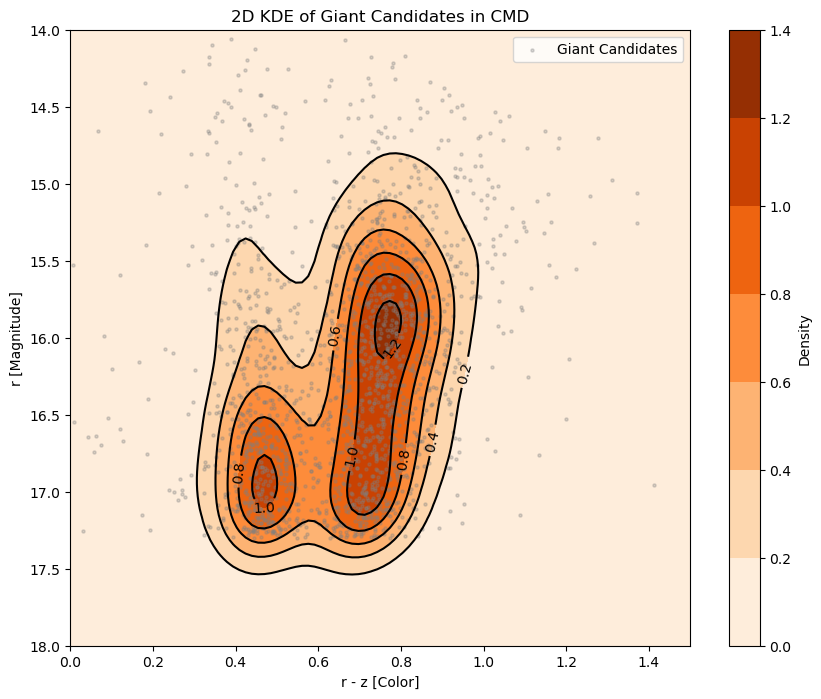

In [7]:
# === Calculate the 2D KDE for Giant and Red Clump Candidates ===
# Code Reference: https://stackoverflow.com/questions/30145957/plotting-2d-kernel-density-estimation-with-python and
                # Google Gemini
    
# --- 2D KDE for Giant Candidates ---
# Define x and y for the 2D KDE
x = giant_colors
y = giant_magnitudes

# Ensure that there is enough data for 2D KDE calculation (at least 2 points)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = 0, 1.5
    ymin, ymax = 14, 18

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    # print(f"Shape of x: {x.shape}")
    # print(f"Shape of y: {y.shape}")
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()
    
    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    
    # Invert the y-axis
    ax.invert_yaxis()
    
    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap='Oranges')
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='gray', alpha=0.3, label='Giant Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Giant Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    plt.show()

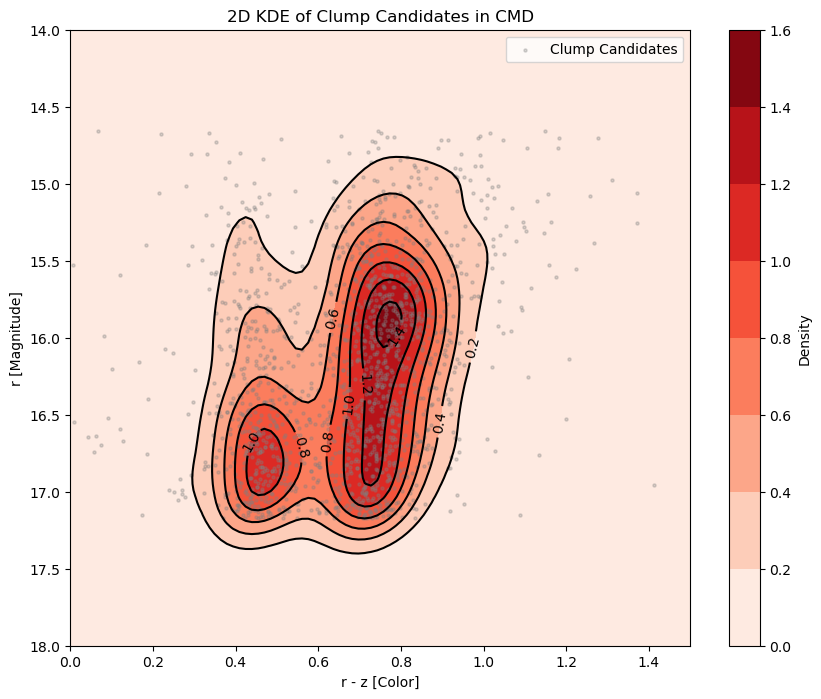

In [8]:
# --- 2D KDE for Red Clump Candidates ---

# Define x and y for the 2D KDE
x = clump_colors
y = clump_magnitudes

# Ensure that there is enough data for 2D KDE calculation (at least 2 points)
if len(x) < 2 or len(y) < 2:
    print("Not enough data points for 2D KDE after filtering. Skipping 2D KDE plot.")
else:
    # Define the plot limits based on your data and CMD parameters
    xmin, xmax = 0, 1.5
    ymin, ymax = 14, 18

    # Peform the kernel density estimate
    xx, yy = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    
    # Stack your x and y data for the KDE calculation
    # print(f"Shape of x: {x.shape}")
    # print(f"Shape of y: {y.shape}")
    values = np.vstack([x, y])
    
    # Create the KDE object
    kernel = st.gaussian_kde(values)
    
    # Evaluate the KDE on the grid
    f = np.reshape(kernel(positions).T, xx.shape)

    # Plotting the 2D KDE
    fig = plt.figure(figsize=(10, 8))
    ax = fig.gca()

    # Set plot limits
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    # Invert the y-axis
    ax.invert_yaxis()
    
    # Contourf plot (filled contours)
    cfset = ax.contourf(xx, yy, f, cmap='Reds')
    
    # You can also add the data points themselves on top of the KDE plot
    ax.scatter(x, y, s=5, color='gray', alpha=0.3, label='Clump Candidates')

    # Contour plot (lines only)
    cset = ax.contour(xx, yy, f, colors='k')
    
    # Label contours
    ax.clabel(cset, inline=1, fontsize=10)
    
    # Set labels and title
    ax.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
    ax.set_ylabel(f"{magnitude_band} [Magnitude]")
    ax.set_title('2D KDE of Clump Candidates in CMD')

    plt.colorbar(cfset, label='Density') # Add a color bar
    plt.legend()
    plt.show()